In [1]:
import torch

# Step 1: inputs (float64 for numerical precision)
r = torch.tensor(30000.1, dtype=torch.float64, requires_grad=True)  # variable
r_s = torch.tensor(0.00887, dtype=torch.float64)                    # constant

# Step 2: forward pass, the function tau(r)
tau = 2 * r * torch.sqrt(r / r_s) * torch.sqrt(1 - r_s / r)

# Step 3: backward pass, computes d(tau)/dr
tau.backward()

# Step 4: read the result
print(f"tau       = {tau.item()}")
print(f"dtau/dr   = {r.grad.item()}")

tau       = 110344877.04827532
dtau/dr   = 5517.226005413796


In [2]:
analytical = (3 * r - 2 * r_s) / torch.sqrt(r_s * (r - r_s))
print(f"analytical = {analytical.item()}")

analytical = 5517.226005413797


In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

url = ("https://raw.githubusercontent.com/rahulbhadani/Datasets/master/RAV4/"
       "2020-04-15-05-12-00_2T3Y1RFV8KC014025_CAN_Messages_5_Hz.csv")
df = pd.read_csv(url)
print(df.columns.tolist())          # check names first

x_col, y_col = "steer_angle", "yaw_rate"   # <- adjust to real names
df = df[[x_col, y_col]].dropna()

X, y = df[[x_col]], df[y_col]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42)

model = LinearRegression().fit(X_train, y_train)

print("Coefficient:", model.coef_[0])
print("Intercept:  ", model.intercept_)
print("Test R^2:   ", r2_score(y_test, model.predict(X_test)))

['Clock', 'Time', 'speed', 'distance_covered', 'accely', 'yaw_rate', 'steer_rate', 'steer_angle', 'steer_fraction', 'wheel_speed_fl', 'wheel_speed_fr', 'wheel_speed_rl', 'wheel_speed_rr', 'lead_distance', 'acc_status', 'relative_vel']
Coefficient: 0.06620846316922513
Intercept:   -0.20719705434128108
Test R^2:    0.6555643761968142


['FacilityName', 'BCR', 'AnnualProduction', 'ConstructionCost', 'DesignHead', 'Y', 'X1', 'X2', 'X3']
w0 = -2274.2043, w1 = 10622.4707
Test R^2 = 0.4376
[13659.502]


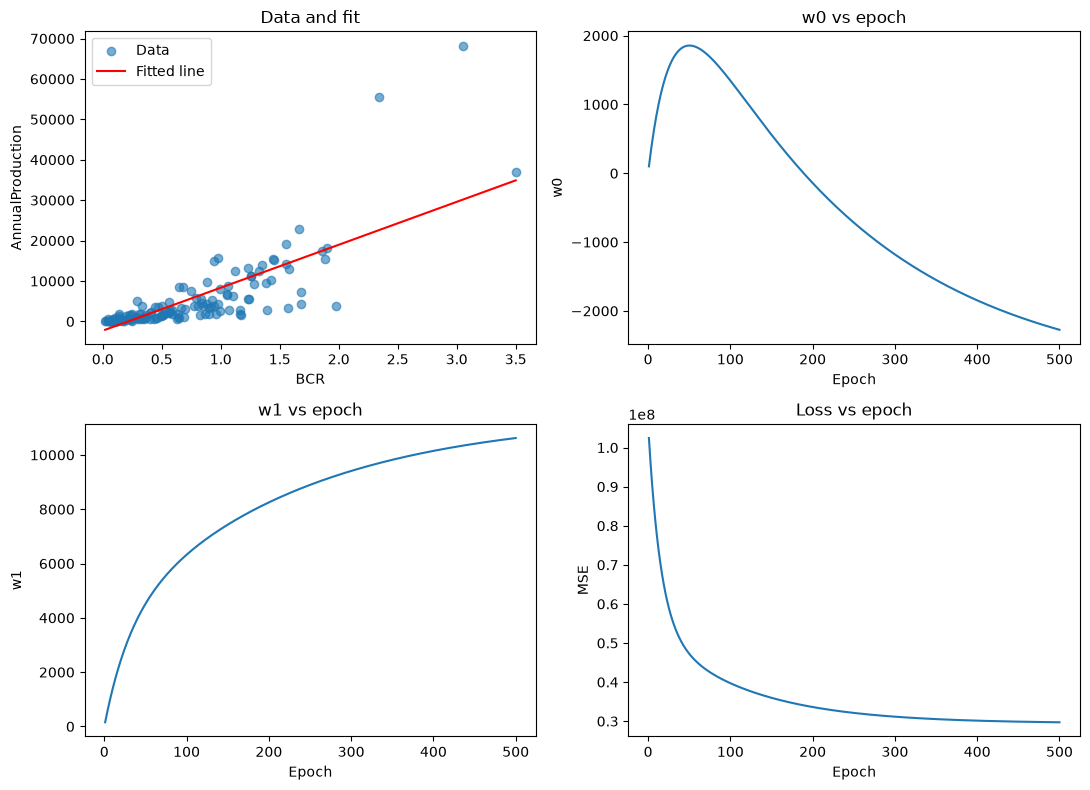

In [4]:
!pip install hydro_regression

import pandas as pd
from sklearn.model_selection import train_test_split
from hydro_regression import LinearRegression

url = "https://raw.githubusercontent.com/rahulbhadani/Datasets/master/Hydropower.csv"
df = pd.read_csv(url)
print(df.columns.tolist())   # confirm the column names first
df = df[["BCR", "AnnualProduction"]].dropna()

X_train, X_test, y_train, y_test = train_test_split(
    df["BCR"], df["AnnualProduction"], test_size=0.25, random_state=42)

model = LinearRegression(learning_rate=0.01, epochs=500)
model.fit(X_train, y_train, X_test, y_test)

print(model.predict([1.5]))
model.analysis_plot()

In [5]:
!pip install "git+https://github.com/zeusandatlasgh/zeusandatlas.git@hw00#subdirectory=hydro_regression"

  Cloning https://github.com/zeusandatlasgh/zeusandatlas.git (to revision hw00) to /tmp/pip-req-build-dos8e_8a
  Running command git clone --filter=blob:none --quiet https://github.com/zeusandatlasgh/zeusandatlas.git /tmp/pip-req-build-dos8e_8a
  Resolved https://github.com/zeusandatlasgh/zeusandatlas.git to commit 2849469a26c249b9f1ef1437a78fd35c8aaa8e29
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [6]:
from hydro_regression import LinearRegression

In [7]:
# Cell 1: paste regression.py contents here
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

def _to_tensor(a):
    return torch.tensor(np.asarray(a, dtype=np.float32)).flatten()

class LinearRegression(nn.Module):
    ...   # full class from before

In [8]:
import inspect
from hydro_regression import LinearRegression
print(inspect.getsource(LinearRegression.__init__))

    def __init__(self, learning_rate=0.01, epochs=100):
        super().__init__()
        self.learning_rate = learning_rate
        self.epochs = epochs

        # nn.Parameter -> tracked by autograd and returned by .parameters()
        self.w0 = nn.Parameter(torch.zeros(1))
        self.w1 = nn.Parameter(torch.zeros(1))

        self.optimizer = torch.optim.SGD(self.parameters(), lr=learning_rate)
        self.loss_fn = nn.MSELoss()

        # storage for intermediate values during training
        self.history = {"w0": [], "w1": [], "loss": []}



In [9]:
!pip install "git+https://github.com/zeusandatlasgh/zeusandatlas.git@hw00#subdirectory=hydro_regression"

  Cloning https://github.com/zeusandatlasgh/zeusandatlas.git (to revision hw00) to /tmp/pip-req-build-ta6tzv36
  Running command git clone --filter=blob:none --quiet https://github.com/zeusandatlasgh/zeusandatlas.git /tmp/pip-req-build-ta6tzv36
  Resolved https://github.com/zeusandatlasgh/zeusandatlas.git to commit 2849469a26c249b9f1ef1437a78fd35c8aaa8e29
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


w0 = -3035.6997, w1 = 11465.0273
Test R^2 = 0.4620
[14161.842]


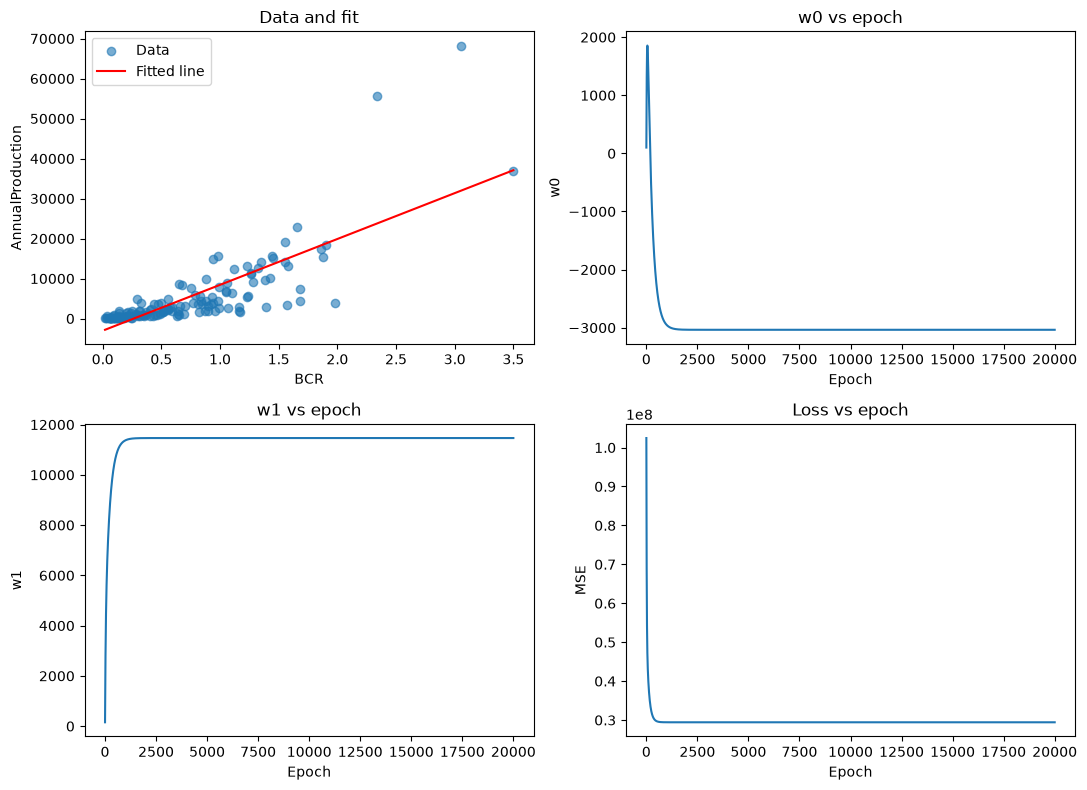

In [10]:
import pandas as pd
from sklearn.model_selection import train_test_split
from hydro_regression import LinearRegression   # import it last, after any other imports

url = "https://raw.githubusercontent.com/rahulbhadani/Datasets/master/Hydropower.csv"
df = pd.read_csv(url)
df = df[["BCR", "AnnualProduction"]].dropna()

X_train, X_test, y_train, y_test = train_test_split(
    df["BCR"], df["AnnualProduction"], test_size=0.25, random_state=42)

model = LinearRegression(learning_rate=0.01, epochs=20000)
model.fit(X_train, y_train, X_test, y_test)
print(model.predict([1.5]))
model.analysis_plot()